# 工具返回之后，再做下一步决策 / Multi-turn Agent

任务要求先查询两个数，再求和并加倍。计算器即使最后给出正确数字，
也不能说明前面的查询动作没有贡献：没有查询返回的数字，后面的计算就没有输入。
我们把这条依赖做成真实的环境接口，再用整条轨迹的回报更新工具选择策略。

默认 CPU、两个种子、160 次策略更新，无外部数据。策略是小型神经网络，
选择工具动作；环境提供调用顺序，策略学习两个计算步骤的选择。


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import os
from pathlib import Path
import numpy as np
import torch

torch.set_num_threads(1)
OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "agentic-tools"
OUTPUT.mkdir(parents=True, exist_ok=True)
training = [{"kind": i % 2, "x": i + 2, "y": i % 5 + 1} for i in range(24)]
heldout = [{"kind": i % 2, "x": i + 32, "y": i % 7 + 1} for i in range(16)]
assert {t["x"] for t in training}.isdisjoint(t["x"] for t in heldout)
print({"training_tasks": len(training), "heldout_tasks": len(heldout), "seeds": [3, 7]})


{'training_tasks': 24, 'heldout_tasks': 16, 'seeds': [3, 7]}


## 1. 观测要来自工具 / Observations from tools

第一类任务查询后求和、加倍；第二类任务查询后求差、平方。
请求中的任务类型公开可见，真实数字在查询后返回。合法动作只限制接口顺序，
求和与求差、加倍与平方始终需要策略选择，标准答案不进入观测。


In [2]:
class ToolEnvironment:
    actions = ["lookup", "add", "subtract", "double", "square", "finish"]
    max_turns = 5

    def __init__(self, task):
        self.task, self.stage, self.value = task, 0, None
        self.success, self.numbers = False, None

    def observe(self):
        state = [float(self.task["kind"] == k) for k in range(2)]
        state += [float(self.stage == k) for k in range(4)]
        state += [value / 100 for value in (self.numbers or [0, 0])]
        state += [0.0 if self.value is None else self.value / 10000]
        legal = [False] * len(self.actions)
        for action in [[0], [1, 2], [3, 4], [5]][self.stage]:
            legal[action] = True
        return state, legal

    def step(self, action):
        assert self.observe()[1][action]
        if action == 0:
            x, y = self.task["x"], self.task["y"]
            self.numbers, self.stage = (x, y), 1
            return -0.01, False, {"x": x, "y": y}
        x, y = self.numbers
        if action in [1, 2]:
            self.value = x + y if action == 1 else x - y
            self.stage = 2
        elif action in [3, 4]:
            self.value = 2 * self.value if action == 3 else self.value ** 2
            self.stage = 3
        else:
            expected = 2 * (x + y) if self.task["kind"] == 0 else (x - y) ** 2
            self.success = self.value == expected
            return float(self.success), True, {"answer": self.value}
        return -0.01, False, {"calculator_result": self.value}


demo = ToolEnvironment(training[0])
for action in [0, 1, 3, 5]:
    print(demo.actions[action], demo.step(action))
assert demo.success


lookup (-0.01, False, {'x': 2, 'y': 1})
add (-0.01, False, {'calculator_result': 3})
double (-0.01, False, {'calculator_result': 6})
finish (1.0, True, {'answer': 6})


## 2. 终局奖励也会更新早期动作 / Credit assignment

四步奖励为 `[0, 0, 0, 1]`、折扣为 0.9 时，第一步的回报是 0.729，
因此早期动作仍有学习信号。稀疏奖励的困难在于方差和探索，不能直接推断早期梯度为零。
查询与提交由协议固定，训练主要改变中间两个工具选择。
上面的折扣用于数值示例，下面训练使用不折扣的轨迹总回报。
训练使用 REINFORCE 和同一请求下其他轨迹的平均回报作为基线；工具返回仅作为下一轮输入。


In [3]:
returns = [0.9 ** 3, 0.9 ** 2, 0.9, 1.0]
assert abs(returns[0] - 0.729) < 1e-10
logits = torch.zeros(8, 2, requires_grad=True)
action_mask = torch.tensor([1, 0, 0, 1, 0, 1, 0, 1], dtype=torch.float32)
selected_logprobs = logits.log_softmax(dim=-1)[:, 0]
loss = -(selected_logprobs * action_mask * 0.729).sum()
loss.backward()
assert (logits.grad[action_mask == 0] == 0).all()
assert logits.grad[0].abs().sum() > 0
print("Discounted returns:", returns, "\nAction/observation gradient:", logits.grad.tolist())


Discounted returns: [0.7290000000000001, 0.81, 0.9, 1.0] 
Action/observation gradient: [[-0.3644999861717224, 0.3644999861717224], [-0.0, 0.0], [-0.0, 0.0], [-0.3644999861717224, 0.3644999861717224], [-0.0, 0.0], [-0.3644999861717224, 0.3644999861717224], [-0.0, 0.0], [-0.3644999861717224, 0.3644999861717224]]


In [4]:
import random

import numpy as np
import torch
from torch import nn


class AgentPolicy(nn.Module):
    def __init__(self, dimensions, actions):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dimensions, 32), nn.Tanh(), nn.Linear(32, actions))

    def forward(self, observation, legal):
        logits = self.net(torch.tensor(observation, dtype=torch.float32))
        return logits.masked_fill(~torch.tensor(legal, dtype=torch.bool), -1e9)


def rollout(policy, task, factory, greedy=False, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    env = factory(task)
    logprobs, entropies, trace, rewards = [], [], [], []
    for turn in range(env.max_turns):
        observation, legal = env.observe()
        distribution = torch.distributions.Categorical(logits=policy(observation, legal))
        action = distribution.logits.argmax() if greedy else distribution.sample()
        logprobs.append(distribution.log_prob(action))
        entropies.append(distribution.entropy())
        reward, done, response = env.step(int(action))
        rewards.append(reward)
        trace.append({"turn": turn, "action": env.actions[int(action)],
                      "observation": response, "reward": reward})
        if done:
            break
    success = bool(env.success)
    if hasattr(env, "close"):
        env.close()
    return {"return": float(sum(rewards)), "success": success, "trace": trace,
            "logprob": torch.stack(logprobs).sum(),
            "entropy": torch.stack(entropies).sum()}


@torch.no_grad()
def evaluate_agent(policy, tasks, factory, greedy=True):
    samples = [rollout(policy, task, factory, greedy=greedy, seed=10000 + i)
               for i, task in enumerate(tasks)]
    return {"success_rate": float(np.mean([item["success"] for item in samples])),
            "return": float(np.mean([item["return"] for item in samples])),
            "mean_turns": float(np.mean([len(item["trace"]) for item in samples]))}


def train_agent(factory, tasks, heldout, seed, updates=160):
    torch.manual_seed(seed)
    rng = random.Random(seed)
    probe = factory(tasks[0])
    policy = AgentPolicy(len(probe.observe()[0]), len(probe.actions))
    if hasattr(probe, "close"):
        probe.close()
    before = evaluate_agent(policy, heldout, factory)
    optimizer = torch.optim.Adam(policy.parameters(), lr=3e-3)
    history = []
    for update in range(updates):
        losses = []
        for task in rng.choices(tasks, k=4):
            group = [rollout(policy, task, factory) for _ in range(4)]
            total = sum(item["return"] for item in group)
            for item in group:
                baseline = (total - item["return"]) / (len(group) - 1)
                advantage = item["return"] - baseline
                losses.append(-item["logprob"] * advantage - 0.002 * item["entropy"])
        optimizer.zero_grad()
        loss = torch.stack(losses).mean()
        loss.backward()
        nn.utils.clip_grad_norm_(policy.parameters(), 2)
        optimizer.step()
        if update % 20 == 0 or update == updates - 1:
            history.append({"update": update, "loss": float(loss.detach()),
                            **evaluate_agent(policy, heldout, factory)})
    after = evaluate_agent(policy, heldout, factory)
    return policy, before, after, history


def run_comparison(factory, training, heldout, output, updates=160):
    results, policies, curves = [], [], []
    for seed in [3, 7]:
        policy, before, after, history = train_agent(
            factory, training, heldout, seed, updates=updates)
        results.append({"seed": seed, "before": before, "after": after})
        policies.append(policy)
        curves.append(history)
    for row in results:
        print(row)
    import json
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for row, curve in zip(results, curves):
        ax.plot([point["update"] for point in curve],
                [point["success_rate"] for point in curve], label=f"seed {row['seed']}")
    ax.set(xlabel="Policy update", ylabel="Held-out greedy success", ylim=(-0.05, 1.05))
    ax.legend()
    fig.tight_layout()
    fig.savefig(output / "training.png", dpi=120)
    plt.show()
    trace = rollout(policies[0], heldout[0], factory, greedy=True)["trace"]
    print(json.dumps(trace, indent=2))
    torch.save(policies[0].state_dict(), output / "policy-seed3.pt")
    metrics = {"runs": results, "fixed_heldout_trace": trace,
               "train_tasks": len(training), "heldout_tasks": len(heldout),
               "updates": updates, "algorithm": "REINFORCE with leave-one-out baseline"}
    assert all(np.isfinite(row["after"]["return"]) for row in results)
    (output / "metrics.json").write_text(json.dumps(metrics, indent=2))
    return policies, metrics


print("Agent contract: observe → action → tool observation → next decision → verifier")


Agent contract: observe → action → tool observation → next decision → verifier


{'seed': 3, 'before': {'success_rate': 0.5, 'return': 0.47, 'mean_turns': 4.0}, 'after': {'success_rate': 1.0, 'return': 0.97, 'mean_turns': 4.0}}
{'seed': 7, 'before': {'success_rate': 0.0, 'return': -0.03, 'mean_turns': 4.0}, 'after': {'success_rate': 1.0, 'return': 0.97, 'mean_turns': 4.0}}


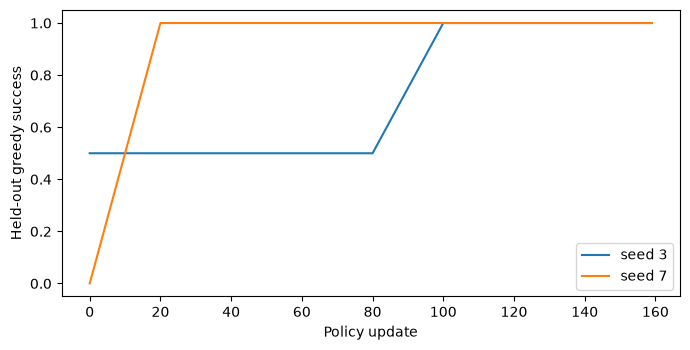

[
  {
    "turn": 0,
    "action": "lookup",
    "observation": {
      "x": 32,
      "y": 1
    },
    "reward": -0.01
  },
  {
    "turn": 1,
    "action": "add",
    "observation": {
      "calculator_result": 33
    },
    "reward": -0.01
  },
  {
    "turn": 2,
    "action": "double",
    "observation": {
      "calculator_result": 66
    },
    "reward": -0.01
  },
  {
    "turn": 3,
    "action": "finish",
    "observation": {
      "answer": 66
    },
    "reward": 1.0
  }
]


In [5]:
policies, metrics = run_comparison(ToolEnvironment, training, heldout, OUTPUT)


## 3. 从轨迹看策略 / Inspect the trajectory

曲线来自未训练过的数字组合，前后都使用贪心策略评估，种子与预算保持一致。
轨迹逐步记录查询、计算和回答，能检查策略是否实际使用了工具返回。
可以去掉调用顺序约束，继续比较工具探索与训练曲线。


In [6]:
assert len(metrics["fixed_heldout_trace"]) == 4
for task in heldout:
    episode = rollout(policies[0], task, ToolEnvironment, greedy=True)
    assert episode["trace"][0]["observation"]["x"] == task["x"]
print("Verified that each held-out trajectory receives its actual lookup result.")


Verified that each held-out trajectory receives its actual lookup result.


## 完成检查 / Checklist
- [ ] 能从终局奖励算出早期动作的非零回报。
- [ ] 能区分策略选择、合法动作约束与环境返回。
- [ ] 保存独立评估曲线、完整轨迹和策略参数。

## 练习 / Exercise
填入四步任务中 γ=0.9 时第一步的回报。提示：最后的 1 分折扣三次。


In [7]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert abs(answer - 0.729) < 1e-6
else:
    print("Fill answer, then enable RUN_EXERCISE.")


Fill answer, then enable RUN_EXERCISE.


## 参考资料 / References
- [多轮 RL](https://walkinglabs.github.io/hands-on-modern-rl/chapter22_agentic/formulation)：
  连接动作、工具观测、轨迹与动作掩码。
- [信用分配](https://walkinglabs.github.io/hands-on-modern-rl/chapter22_agentic/credit-assignment)：
  讨论终局奖励怎样作用于多轮策略。


## 本次运行结果

CPU · Python 3.12.13 · 4.32 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/agentic-tools-zh.html)
